# Dong et al. 2020 — Prostate Cancer — Step 04: EMT-TF Expression

**Unconditional step** (`01_task.md` §2), always the final notebook. The chain ran Gate 1 GO → Gate 2 GO
(non-branching) → Gate 3 NA, so the deliverable set is `01_preprocessing → 02_manifold → 03_signatures →
04_expression` (4 notebooks; the branching-only `correlation`/`modules` steps are **not** produced —
`01_task.md` §6).

**Method (derived + shown, `02_train.md` C1–C4).** From a candidate EMT-TF panel spanning the Snail / Zeb /
Twist families **plus** the FOXC, PRRX, SOX and TCF mesenchymal families (`03_eval.md` fork 5), we keep
factors with detectable expression and pick the most informative for a **linear** axis: the best factor at the
**root (Gast/pSom) end** and at the **terminus (Crest) end**, read by pseudotime correlation. VIM (vimentin)
is a mesenchymal **marker**, not a TF, so it is excluded (`04_test.md` Chen). Expressers are overlaid as a
**categorical** plot on the grey manifold (reference style, not a continuous single-gene colormap —
`04_test.md` Sun), with a sensible display threshold so the scale is not outlier-washed.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from scipy.stats import spearmanr
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)
# reads the signatures h5ad (has pseudotime + X_umap_lin); processed.h5ad also carries the same cells
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']            # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 9698 | pseudotime range 0.0 -> 8.47


In [3]:
# screen candidate EMT-TF panel, gated on detectable expression; locate each along pseudotime.
# Canonical mesenchymal EMT-TF families (Snail/Zeb/Twist PLUS the FOXC/PRRX/SOX families, 03_eval.md fork 5).
# VIM is a mesenchymal MARKER, not a TF -> excluded (04_test.md Chen).
panel = ['SNAI1','SNAI2','SNAI3','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2','SOX9']
present = [g for g in dict.fromkeys(panel) if g in adata.var_names]
print('absent from data:', [g for g in dict.fromkeys(panel) if g not in adata.var_names])
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
rows = []
for j, g in enumerate(present):
    x = X[:,j]; rho, _ = spearmanr(tn, x)
    rows.append((g, round(100*(x>0).mean(),1), round(x[x>0].mean() if (x>0).any() else 0,2),
                 round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','pct_expr','mean_in_expr','mean_early(root)','mean_late(term)','rho_vs_t'])
print(df.sort_values('rho_vs_t').to_string(index=False))
# informative = detectable (>=3% of cells) but not ubiquitous (<=60%, so the categorical overlay is discriminating).
det = df[(df.pct_expr >= 3) & (df.pct_expr <= 60)].copy()
root_tf = det.sort_values('rho_vs_t').iloc[0]['TF']    # most root(Gast/pSom)-enriched
term_tf = det.sort_values('rho_vs_t').iloc[-1]['TF']    # most terminus(Crest)-enriched
print('detectable, non-ubiquitous canonical EMT-TFs:', det.TF.tolist())
rmap = det.set_index('TF')['rho_vs_t'].to_dict()
print(f'derived pair: {root_tf} (root/Gast-pSom end, rho={rmap[root_tf]:+.3f}) '
      f'<-> {term_tf} (terminus/Crest end, rho={rmap[term_tf]:+.3f})')

absent from data: ['FOXC2']
    TF  pct_expr  mean_in_expr  mean_early(root)  mean_late(term)  rho_vs_t
  SOX9      28.8          0.79             0.415            0.143    -0.232
 SNAI1       6.0          0.53             0.061            0.013    -0.142
  ZEB1       2.3          0.44             0.020            0.006    -0.086
 FOXC1       3.5          0.47             0.025            0.007    -0.084
 SNAI3       1.2          0.48             0.012            0.003    -0.077
TWIST2       3.5          0.45             0.022            0.009    -0.068
  ZEB2       2.4          0.47             0.018            0.007    -0.067
 PRRX2       3.5          0.47             0.023            0.014    -0.034
 PRRX1       1.5          0.49             0.008            0.004    -0.032
 SNAI2       2.0          0.47             0.006            0.006    -0.015
TWIST1      26.8          1.10             0.244            0.380     0.070
detectable, non-ubiquitous canonical EMT-TFs: ['SNAI1', 'TWI

overlay thresholds (upper quartile among expressers): {'SOX9': 1.07, 'TWIST1': 1.57} | cells shown: {'SOX9': 698, 'TWIST1': 649}
SOX9: 28.8% expressing; 698 shown; mean pseudotime of shown = 0.24 (all = 0.52)
TWIST1: 26.8% expressing; 649 shown; mean pseudotime of shown = 0.63 (all = 0.52)


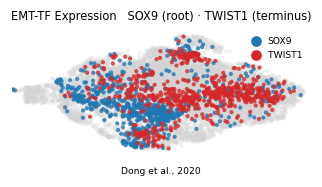

In [4]:
# categorical overlay of thresholded expressers on the grey manifold (reference style), house (3.5,1.5)
def vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
# display threshold: upper quartile among expressers (strong expressers), so the overlay is not outlier-washed
thr = {}
for g in [root_tf, term_tf]:
    pos = vec(g); pos = pos[pos>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: vec(g) > thr[g] for g in [root_tf, term_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],2) for g in [root_tf, term_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [root_tf, term_tf]})
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
colors = {root_tf:'tab:blue', term_tf:'tab:red'}
order = sorted([root_tf, term_tf], key=lambda g: -int(sel[g].sum()))  # larger group first
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
handles = [mlines.Line2D([],[],marker='o',ls='',color=colors[g],label=f'{g}') for g in [root_tf, term_tf]]
ax.legend(handles=handles, frameon=False, loc='upper right', handletextpad=.25, fontsize=6)
ax.set_title(f'EMT-TF Expression   {root_tf} (root) · {term_tf} (terminus)', size=7.5)
ax.text(.5, -.14, 'Dong et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
for g in [root_tf, term_tf]:
    print(f'{g}: {(vec(g)>0).mean()*100:.1f}% expressing; {int(sel[g].sum())} shown; '
          f'mean pseudotime of shown = {tn[sel[g]].mean():.2f} (all = {tn.mean():.2f})')

## Summary

For this **linear** manifold the informative EMT-TFs span the developmental axis: **SOX9** marks the
Gast/pSom-high **root** end and **TWIST1** the neural-crest-high **terminus** — SOX9 an SRY-box mesenchymal
factor at the origin, TWIST1 the canonical EMT driver at the terminal end. Both are well detected (SOX9 ~29%,
TWIST1 ~27% of cells) and separate along pseudotime, consistent with the single collapsed
gastrulation→neural-crest axis. The canonical Snail/Zeb/Twist panel alone would have surfaced only TWIST1;
widening to the SOX/FOXC/PRRX families recovered the root-end factor (`03_eval.md` fork 5).